In [14]:
from pathlib import Path
 
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [20]:
DATA_DIR = Path(r"D:\Universitas Hasanuddin\Semester 5 (2026)\Kecerdasan Artifisial Geofisika")
FILENAME = "POWER_Point_Daily_20250101_20251231_005d14S_119d43E_LST.csv"
VARIABLE = "PRECTOTCORR"
LABEL = "Curah hujan harian"
UNIT = "mm/day"
FILL_VALUE = -999.0          
ROLL_WINDOW = 7              
OUT_DIR = DATA_DIR / "output_R-VIS-001"

def read_power_csv(path):
    """Baca CSV NASA POWER: deteksi otomatis baris header, buat kolom tanggal."""
    path = Path(path)
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        lines = f.read().splitlines()
    # baris kolom = baris pertama setelah '-END HEADER-'
    skip = next(i for i, ln in enumerate(lines) if "END HEADER" in ln) + 1
    df = pd.read_csv(path, skiprows=skip)
    df["date"] = pd.to_datetime(df["YEAR"].astype(str), format="%Y") + pd.to_timedelta(
        df["DOY"] - 1, unit="D"
    )
    df = df.set_index("date").sort_index()
    return df

def find_gaps(series):
    """Kembalikan daftar (start, end) interval missing berturut-turut."""
    isna = series.isna().to_numpy()
    gaps, start = [], None
    for i, flag in enumerate(isna):
        if flag and start is None:
            start = i
        if not flag and start is not None:
            gaps.append((series.index[start], series.index[i - 1]))
            start = None
    if start is not None:
        gaps.append((series.index[start], series.index[-1]))
    return gaps
 
 
def plot_timeseries(series, label, unit, roll_window=7, figsize=(3.5, 2.4),
                    title=None, event_quantile=0.99):
    """
    Plot time series satu kolom paper.
    - batang tipis  : observasi harian (hujan = akumulasi, bar lebih tepat dari garis)
    - garis tebal   : rata-rata bergerak (tren)
    - blok abu-abu  : interval missing (tidak dihubungkan)
    - titik merah   : event ekstrem (>= kuantil tertentu), data tidak diubah
    """
    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
 
    # Observasi: bar; NaN otomatis tidak digambar -> tidak ada penghubung gap
    ax.bar(series.index, series.values, width=1.0, color="#6baed6",
           edgecolor="none", label="Harian", zorder=2)
 
    # Tren: rolling mean (min_periods agar NaN tidak diisi / diinterpolasi)
    trend = series.rolling(roll_window, center=True, min_periods=roll_window).mean()
    ax.plot(trend.index, trend.values, color="#08306b", lw=1.1,
            label=f"Rata-rata {roll_window} hari", zorder=3)
 
    # Event ekstrem
    thr = series.quantile(event_quantile)
    ev = series[series >= thr]
    ax.scatter(ev.index, ev.values, s=10, color="#d7301f", zorder=4,
               label=f"Event ≥ P{int(event_quantile*100)} ({thr:.0f})")
 
    # Gap
    for k, (a, b) in enumerate(find_gaps(series)):
        ax.axvspan(a - pd.Timedelta(hours=12), b + pd.Timedelta(hours=12),
                   color="0.7", alpha=0.5, zorder=1,
                   label="Missing" if k == 0 else None)
 
    ax.set_ylabel(f"{label} ({unit})", fontsize=7)
    ax.set_xlabel("Waktu", fontsize=7)
    ax.set_ylim(bottom=0)
    ax.set_xlim(series.index.min(), series.index.max())
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.tick_params(labelsize=7)
    ax.grid(axis="y", lw=0.3, alpha=0.5)
    ax.legend(fontsize=5.5, frameon=False, loc="upper left", ncol=1)
    if title:
        ax.set_title(title, fontsize=7.5)
    return fig, ax
 
 
def main():
    df = read_power_csv(DATA_DIR / FILENAME)
    s = df[VARIABLE].astype(float).replace(FILL_VALUE, np.nan)
 
    n_miss = int(s.isna().sum())
    print(f"Jumlah data   : {len(s)} hari ({s.index.min().date()} s/d {s.index.max().date()})")
    print(f"Missing       : {n_miss} hari; gap: {find_gaps(s) or 'tidak ada'}")
    print(f"Min/Mean/Max  : {s.min():.2f} / {s.mean():.2f} / {s.max():.2f} {UNIT}")
    print(f"Total tahunan : {s.sum():.1f} mm")
 
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    title = "NASA POWER, Makassar (−5.14°, 119.43°), 2025"
 
    # Exploratory PNG (lebih besar, untuk dilihat di layar)
    fig, _ = plot_timeseries(s, LABEL, UNIT, ROLL_WINDOW, figsize=(7, 3.2), title=title)
    fig.savefig(OUT_DIR / "r-vis-001_exploratory.png", dpi=200)
    plt.close(fig)
 
    # Publication PDF (lebar satu kolom paper)
    fig, _ = plot_timeseries(s, LABEL, UNIT, ROLL_WINDOW, figsize=(3.5, 2.6))
    fig.savefig(OUT_DIR / "r-vis-001_publication.pdf")
    plt.close(fig)
 
    print(f"Selesai. Output di: {OUT_DIR}")
 
 
if __name__ == "__main__":
    main()


Jumlah data   : 365 hari (2025-01-01 s/d 2025-12-31)
Missing       : 0 hari; gap: tidak ada
Min/Mean/Max  : 0.00 / 6.37 / 100.41 mm/day
Total tahunan : 2324.6 mm
Selesai. Output di: D:\Universitas Hasanuddin\Semester 5 (2026)\Kecerdasan Artifisial Geofisika\output_R-VIS-001


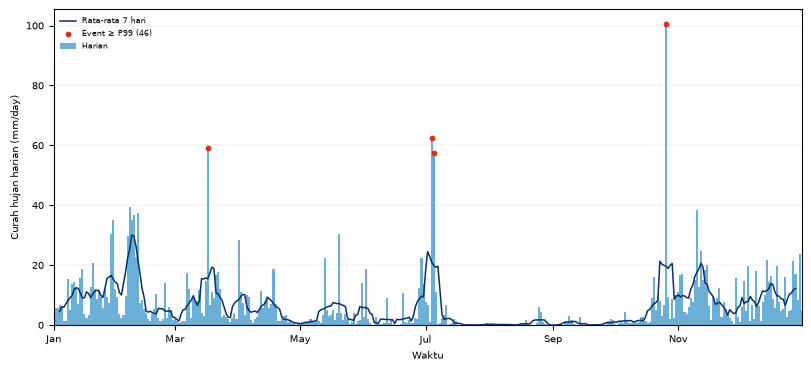

In [21]:
df = read_power_csv(DATA_DIR / FILENAME)
s = df[VARIABLE].astype(float).replace(FILL_VALUE, np.nan)
fig, ax = plot_timeseries(s, LABEL, UNIT, ROLL_WINDOW, figsize=(8, 3.6))
plt.show()